# Longitudinal Trend and Shift Analysis of GHG Emissions at the Detroit Refinery (2010–2019)
IT 50700 term project: Yamjala Madhav, Shraddha Upadhyay, Robin Sajedul Alam

**How to use this notebook**
- Section 0 (setup) is shared and already works. Do not change it without telling the group.
- Each person works **only in their own section** (A, B or C). Replace the `TODO` cells with your code.
- Save figures with `save_fig(...)` (they go to `code/figures/`), and record every test with `add_result(...)` so Section D can build the results table.
- Before sending the notebook back, run **Kernel → Restart & Run All** and make sure it finishes without errors.
- Significance level: α = 0.05 for every test.

## 0. Setup (shared)

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd() / 'code'
DATA, MODELS, FIGURES, RESULTS = (ROOT / d for d in ('data', 'models', 'figures', 'results'))
ALPHA = 0.05

plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 12, 'figure.dpi': 120})

def save_fig(fig, name):
    # Saves a numbered figure (e.g. 'fig1_time_series') as PNG for the paper and slides
    fig.savefig(FIGURES / f'{name}.png', dpi=300, bbox_inches='tight')

results = []

def add_result(hypothesis, test, statistic, p_value, owner):
    decision = 'Reject H0' if p_value < ALPHA else 'Fail to reject H0'
    results.append(dict(hypothesis=hypothesis, test=test, statistic=round(float(statistic), 4),
                        p_value=round(float(p_value), 4), decision=decision, owner=owner))

In [2]:
df = pd.read_csv(DATA / 'Detroit_Refinery_GHG_2010_2019.csv')
years = df['year'].to_numpy()
y = df['total_direct_tCO2e'].to_numpy()  # metric tons CO2e, Subparts C + Y
group1 = df.loc[df['period'] == '2010-2014', 'total_direct_tCO2e'].to_numpy()
group2 = df.loc[df['period'] == '2015-2019', 'total_direct_tCO2e'].to_numpy()
df

,year,period,subpart_C_combustion_tCO2e,subpart_Y_refining_tCO2e,total_direct_tCO2e
0,2010,2010-2014,414201.39,220352.88,634554.27
1,2011,2010-2014,480441.66,244497.51,724939.17
2,2012,2010-2014,503212.74,234875.13,738087.87
3,2013,2010-2014,572626.18,306132.68,878758.86
4,2014,2010-2014,604305.98,302247.68,906553.66
5,2015,2015-2019,591411.83,293256.22,884668.05
6,2016,2015-2019,587471.56,309108.14,896579.70
7,2017,2015-2019,524670.86,298850.49,823521.35
8,2018,2015-2019,558951.46,266452.28,825403.74
9,2019,2015-2019,589128.94,273726.94,862855.88


**Data notes.** Source: EPA GHGRP via Envirofacts (`PUB_FACTS_SECTOR_GHG_EMISSION`, facility ID 1006388), listed on Data.gov.
`total_direct_tCO2e` is the refinery sector only (Subpart C stationary combustion + Subpart Y petroleum refining).
The much larger "Petroleum Product Suppliers" figure under the same facility ID is excluded because it is the
emissions from burning the fuel the refinery sells, not on-site emissions. The cell below re-downloads the data; it is off by default.

In [3]:
REFRESH_FROM_EPA = False

if REFRESH_FROM_EPA:
    url = 'https://data.epa.gov/efservice/PUB_FACTS_SUBP_GHG_EMISSION/FACILITY_ID/1006388/JSON'
    raw = pd.read_json(url)
    raw = raw[raw['year'].between(2010, 2019) & raw['sub_part_id'].isin([1, 22])]  # 1 = Subpart C, 22 = Subpart Y
    wide = raw.pivot_table(index='year', columns='sub_part_id', values='co2e_emission', aggfunc='sum')
    wide.columns = ['subpart_C_combustion_tCO2e', 'subpart_Y_refining_tCO2e']
    wide['total_direct_tCO2e'] = wide.sum(axis=1)
    wide.insert(0, 'period', np.where(wide.index < 2015, '2010-2014', '2015-2019'))
    wide.round(2).to_csv(DATA / 'Detroit_Refinery_GHG_2010_2019.csv')

## A. Exploratory data analysis (should be done by everyone individually)
Outputs: `results/descriptive_stats.csv`, `results/eda_yearly_table.csv`, Figure 1 (time series) and four EDA figures.

### A1. Data quality checks

In [4]:
checks = {
    'ten annual values': len(df) == 10,
    'years 2010-2019, no gaps': list(years) == list(range(2010, 2020)),
    'no missing values': not df.isna().any().any(),
    'total = Subpart C + Subpart Y': np.allclose(df['total_direct_tCO2e'],
                                                 df['subpart_C_combustion_tCO2e'] + df['subpart_Y_refining_tCO2e'], atol=0.02),
    'period labels match years': (df['period'] == np.where(years < 2015, '2010-2014', '2015-2019')).all(),
    'all values positive': (df.select_dtypes('number').drop(columns='year') > 0).all().all(),
}
for name, ok in checks.items():
    print(f'{"PASS" if ok else "FAIL"}  {name}')
assert all(checks.values()), 'Fix the data file before running the tests'

PASS  ten annual values
PASS  years 2010-2019, no gaps
PASS  no missing values
PASS  total = Subpart C + Subpart Y
PASS  period labels match years
PASS  all values positive


### A2. Descriptive statistics

In [5]:
def describe(values):
    values = np.asarray(values, dtype=float)
    return {'n': len(values), 'mean': values.mean(), 'median': np.median(values), 'std': values.std(ddof=1),
            'cv_percent': 100 * values.std(ddof=1) / values.mean(), 'min': values.min(), 'max': values.max(),
            'range': np.ptp(values)}

desc = pd.DataFrame({
    'All years (total)': describe(y),
    '2010-2014 (total)': describe(group1),
    '2015-2019 (total)': describe(group2),
    'Subpart C, all years': describe(df['subpart_C_combustion_tCO2e']),
    'Subpart Y, all years': describe(df['subpart_Y_refining_tCO2e']),
}).T
desc.round(1).to_csv(RESULTS / 'descriptive_stats.csv')
desc.round(1)

,n,mean,median,std,cv_percent,min,max,range
All years (total),10.0,817592.3,844129.8,90029.1,11.0,634554.3,906553.7,271999.4
2010-2014 (total),5.0,776578.8,738087.9,113636.9,14.6,634554.3,906553.7,271999.4
2015-2019 (total),5.0,858605.7,862855.9,33438.8,3.9,823521.4,896579.7,73058.3
"Subpart C, all years",10.0,542642.3,565788.8,61246.5,11.3,414201.4,604306.0,190104.6
"Subpart Y, all years",10.0,274950.0,283491.6,32281.0,11.7,220352.9,309108.1,88755.3


### A3. Year-over-year changes and composition

In [6]:
yearly = df[['year', 'subpart_C_combustion_tCO2e', 'subpart_Y_refining_tCO2e', 'total_direct_tCO2e']].copy()
yearly['change_tCO2e'] = yearly['total_direct_tCO2e'].diff()
yearly['change_percent'] = 100 * yearly['total_direct_tCO2e'].pct_change()
yearly['subpart_Y_share_percent'] = 100 * yearly['subpart_Y_refining_tCO2e'] / yearly['total_direct_tCO2e']
yearly['index_2010_100'] = 100 * yearly['total_direct_tCO2e'] / yearly['total_direct_tCO2e'].iloc[0]
yearly.round(2).to_csv(RESULTS / 'eda_yearly_table.csv', index=False)

biggest = yearly.loc[yearly['change_tCO2e'].abs().idxmax()]
print(f"Largest one-year change: {int(biggest['year']) - 1}->{int(biggest['year'])}, "
      f"{biggest['change_tCO2e']:+,.0f} t ({biggest['change_percent']:+.1f}%)")
print(f"Change 2010->2019: {y[-1] - y[0]:+,.0f} t ({100 * (y[-1] / y[0] - 1):+.1f}%)")
r_cy, p_cy = stats.pearsonr(df['subpart_C_combustion_tCO2e'], df['subpart_Y_refining_tCO2e'])
print(f'Subpart C vs Subpart Y correlation: r = {r_cy:.3f}, p = {p_cy:.4f}')
yearly.round(1)

Largest one-year change: 2012->2013, +140,671 t (+19.1%)
Change 2010->2019: +228,302 t (+36.0%)
Subpart C vs Subpart Y correlation: r = 0.838, p = 0.0025


,year,subpart_C_combustion_tCO2e,subpart_Y_refining_tCO2e,total_direct_tCO2e,change_tCO2e,change_percent,subpart_Y_share_percent,index_2010_100
0,2010,414201.4,220352.9,634554.3,NaN,NaN,34.7,100.0
1,2011,480441.7,244497.5,724939.2,90384.9,14.2,33.7,114.2
2,2012,503212.7,234875.1,738087.9,13148.7,1.8,31.8,116.3
3,2013,572626.2,306132.7,878758.9,140671.0,19.1,34.8,138.5
4,2014,604306.0,302247.7,906553.7,27794.8,3.2,33.3,142.9
5,2015,591411.8,293256.2,884668.0,-21885.6,-2.4,33.1,139.4
6,2016,587471.6,309108.1,896579.7,11911.6,1.3,34.5,141.3
7,2017,524670.9,298850.5,823521.4,-73058.3,-8.1,36.3,129.8
8,2018,558951.5,266452.3,825403.7,1882.4,0.2,32.3,130.1
9,2019,589128.9,273726.9,862855.9,37452.1,4.5,31.7,136.0


### A4. Figure 1: annual emissions, 2010–2019

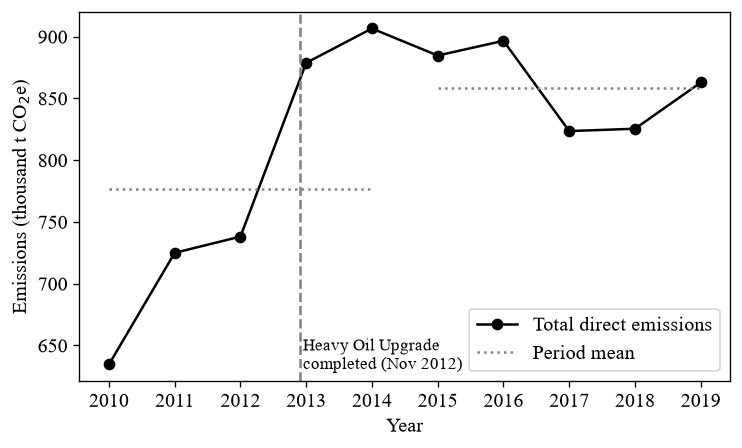

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(years, y / 1e3, 'o-', color='black', label='Total direct emissions')
for grp, yrs_ in ((group1, years[:5]), (group2, years[5:])):
    ax.hlines(grp.mean() / 1e3, yrs_[0], yrs_[-1], colors='gray', linestyles=':', label=None)
ax.axvline(2012.9, color='gray', linestyle='--')
ax.text(2012.95, ax.get_ylim()[0] + 10, 'Heavy Oil Upgrade\ncompleted (Nov 2012)', fontsize=10)
ax.set_xlabel('Year')
ax.set_ylabel('Emissions (thousand t CO$_2$e)')
ax.set_xticks(years)
ax.legend(['Total direct emissions', 'Period mean'], loc='lower right')
save_fig(fig, 'fig1_time_series')

### A5. Emissions by source (Subpart C combustion vs Subpart Y refining)

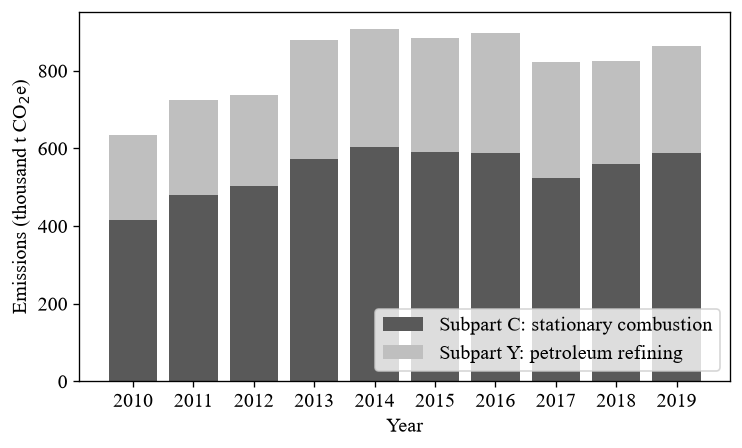

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(years, df['subpart_C_combustion_tCO2e'] / 1e3, color='0.35', label='Subpart C: stationary combustion')
ax.bar(years, df['subpart_Y_refining_tCO2e'] / 1e3, bottom=df['subpart_C_combustion_tCO2e'] / 1e3,
       color='0.75', label='Subpart Y: petroleum refining')
ax.set_xlabel('Year')
ax.set_ylabel('Emissions (thousand t CO$_2$e)')
ax.set_xticks(years)
ax.legend(loc='lower right')
save_fig(fig, 'eda_subpart_composition')

### A6. Year-over-year percentage change

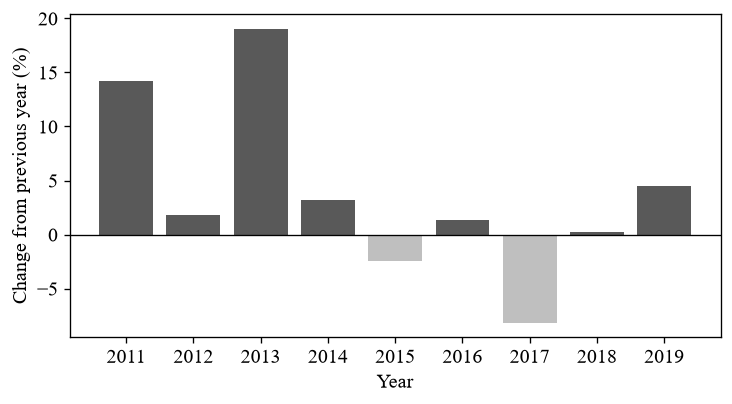

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.5))
chg = yearly['change_percent'].iloc[1:]
ax.bar(years[1:], chg, color=np.where(chg >= 0, '0.35', '0.75'))
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xlabel('Year')
ax.set_ylabel('Change from previous year (%)')
ax.set_xticks(years[1:])
save_fig(fig, 'eda_yoy_change')

### A7. Distribution and outliers

Skewness = -1.068, excess kurtosis = 0.232
Shapiro-Wilk on raw values (descriptive only): W = 0.8721, p = 0.1056
Years with |z| > 2: [2010]
IQR fences: 573,829 to 1,068,808; years outside: none


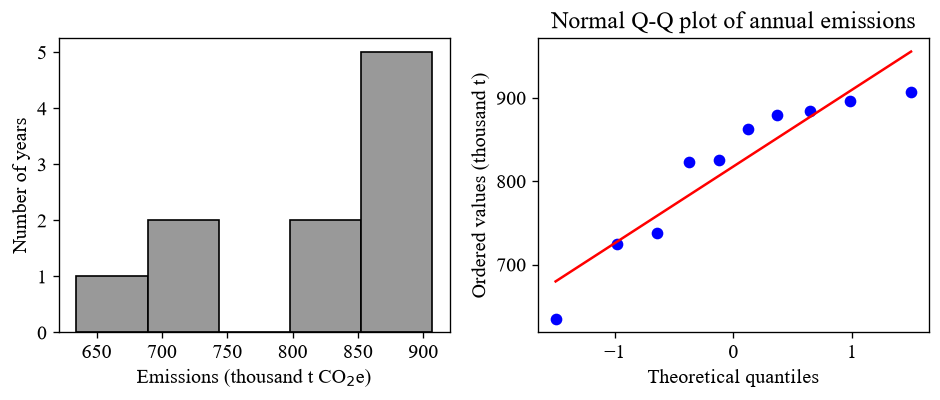

In [10]:
z = (y - y.mean()) / y.std(ddof=1)
q1, q3 = np.percentile(y, [25, 75])
iqr_low, iqr_high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
print(f'Skewness = {stats.skew(y, bias=False):.3f}, excess kurtosis = {stats.kurtosis(y, bias=False):.3f}')
print(f'Shapiro-Wilk on raw values (descriptive only): W = {stats.shapiro(y).statistic:.4f}, p = {stats.shapiro(y).pvalue:.4f}')
print('Years with |z| > 2:', [int(v) for v in years[np.abs(z) > 2]] or 'none')
print(f'IQR fences: {iqr_low:,.0f} to {iqr_high:,.0f}; years outside:', [int(v) for v in years[(y < iqr_low) | (y > iqr_high)]] or 'none')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3.5))
ax1.hist(y / 1e3, bins=5, color='0.6', edgecolor='black')
ax1.set_xlabel('Emissions (thousand t CO$_2$e)')
ax1.set_ylabel('Number of years')
stats.probplot(y / 1e3, dist='norm', plot=ax2)
ax2.set_title('Normal Q-Q plot of annual emissions')
ax2.set_ylabel('Ordered values (thousand t)')
fig.tight_layout()
save_fig(fig, 'eda_distribution')

### A8. Serial dependence in the raw series
A trend by itself makes neighbouring years look alike, so this is a first look; the residual check in A10 is the one that matters for H1.

Lag-1 autocorrelation of annual emissions: r1 = 0.755


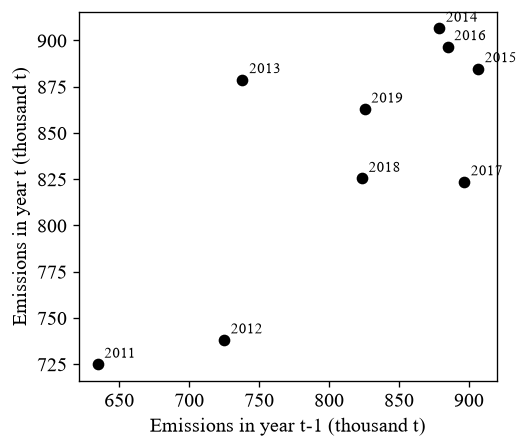

In [11]:
r1_raw = np.corrcoef(y[:-1], y[1:])[0, 1]
print(f'Lag-1 autocorrelation of annual emissions: r1 = {r1_raw:.3f}')

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.scatter(y[:-1] / 1e3, y[1:] / 1e3, color='black')
for yr, a, b in zip(years[1:], y[:-1] / 1e3, y[1:] / 1e3):
    ax.annotate(str(yr), (a, b), textcoords='offset points', xytext=(4, 4), fontsize=9)
ax.set_xlabel('Emissions in year t-1 (thousand t)')
ax.set_ylabel('Emissions in year t (thousand t)')
save_fig(fig, 'eda_lag_plot')

### EDA: key observations
- **Data quality:** all ten years are present with no gaps or missing values, and every total equals Subpart C + Subpart Y.
- **Level:** mean 817,592 t CO$_2$e per year (SD 90,029, CV 11%). Emissions rose 36% from 2010 to 2019.
- **One big jump:** the largest change is 2012→2013 (+140,671 t, +19.1%), right after the Heavy Oil Upgrade was completed. After 2013 the series is flat to slightly falling (Figure 1).
- **Spread by period:** 2010–2014 varies far more (SD 113,637) than 2015–2019 (SD 33,439), because the first period contains the jump. This matters for Levene's test in H2.
- **Sources:** stationary combustion (Subpart C) is about two-thirds of the total and refining processes (Subpart Y) about one-third. The two move together (r = 0.84) and the share barely changes (32–36%), so the jump came from both.
- **Distribution:** skewed left (skewness −1.07) because of the low 2010 value, the only year with |z| > 2. It is not an outlier by the IQR rule and is a real pre-upgrade value, so it stays in.
- **Serial dependence:** strong lag-1 autocorrelation in the raw series (r$_1$ = 0.76). Part of this comes from the trend itself, so A10 should check whether it remains in the H1 residuals.

## A9–A10. H1 linear trend and residual checks (owner: Madhav)
Outputs: `models/h1_linear_model.json`, `results/h1_anova_table.csv`, Figure 2 (residual plots).

In [12]:
# TODO (Madhav) A9: H1 linear regression y = b0 + b1*year (stats.linregress).
# Report slope, its t statistic and p-value, F statistic, R^2, and the regression ANOVA table.
# add_result('H1', 'Linear regression slope t-test', t, p, 'Madhav')
# Save slope, intercept, R^2 and standard errors to MODELS / 'h1_linear_model.json'.
# Keep the variable names b0 and b1: Section C compares Sen's slope with b1.

In [13]:
# TODO (Madhav) A10: H4 (part 1) residual checks for the H1 model.
# Shapiro-Wilk on residuals -> add_result('H4', 'Shapiro-Wilk on H1 residuals', W, p, 'Madhav')
# Durbin-Watson d = sum(diff(e)^2) / sum(e^2); for n = 10, one predictor, alpha = 0.05: dL = 0.879, dU = 1.320
# Figure 2: residuals vs year and a normal Q-Q plot (stats.probplot). save_fig(fig, 'fig2_residuals')

## B. H2 mean shift and sensitivity check (owner: Shraddha)
Outputs: Figure 3 (box plots), H2 results, sensitivity results.

In [14]:
# TODO (Shraddha) B1: H4 (part 2) assumption checks for H2.
# Shapiro-Wilk on group1 and on group2, then Levene's test (stats.levene).
# add_result('H4', 'Shapiro-Wilk 2010-2014', ..., 'Shraddha') and the same for 2015-2019 and Levene.

In [15]:
# TODO (Shraddha) B2: H2 one-way ANOVA (stats.f_oneway) of group1 vs group2.
# If the B1 checks fail, also run Kruskal-Wallis (stats.kruskal). Record both with add_result('H2', ...).
# Figure 3: side-by-side box plots of the two periods. save_fig(fig, 'fig3_boxplots')

In [16]:
# TODO (Shraddha) B3: sensitivity check, ANOVA of 2010-2012 vs 2013-2019 (before vs after the upgrade).
# add_result('H2 sensitivity', 'ANOVA 2010-2012 vs 2013-2019', F, p, 'Shraddha')

## C. H3 monotonic trend (owner: Robin)
Outputs: H3 results, Sen's slope, Figure 4.

In [17]:
# TODO (Robin) C1: H3 Mann-Kendall test, written by hand (no extra package needed).
# S = sum over i<j of sign(y[j] - y[i]);  Var(S) = n(n-1)(2n+5)/18
# Z = (S - 1)/sqrt(Var) if S > 0, (S + 1)/sqrt(Var) if S < 0, else 0;  p = 2*(1 - stats.norm.cdf(abs(Z)))
# Check your answer against stats.kendalltau(years, y). add_result('H3', 'Mann-Kendall', Z, p, 'Robin')

In [18]:
# TODO (Robin) C2: Sen's slope = median of (y[j]-y[i])/(years[j]-years[i]) over all i<j.
# Compare it with the H1 regression slope. Figure 4: data with both the regression line and the Sen's slope line.
# save_fig(fig, 'fig4_trend_lines')

## D. Summary of all tests (owner: Robin)

In [19]:
summary = pd.DataFrame(results)
if results:  # empty until Sections A2, B and C are filled in
    summary.to_csv(RESULTS / 'summary_of_tests.csv', index=False)
summary

""
